<a href="https://colab.research.google.com/github/antoniosolis4536-collab/MIAAD/blob/main/Regresion_Datos_Categoricos.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

** Regresión lineal con datos categóricos: Costos, Localidades y Salarios**

📌 Objetivos de la Práctica:
Al finalizar esta práctica, los estudiantes serán capaces de:

- Codificar variables categóricas usando one-hot encoding con K-1 para problemas de regresión
- Realizar AED
- Construir un modelo de regresión con variables dummy
- Interpretar los resultados de los coeficientes
- Analizar los resultados de los errores residuales
- Calcular el desempeño del modelo de regresión.

Problema: Se podría argumentar que el salario está relacionado con el costo de la educación. Por lo tanto, para analizar este argumentos veremos qué sucede cuando usamos las variables independientes cost y location.

**Nombre:** Antonio Ismael Solís Martínez  
**Matrícula:** 274706

In [19]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


# 1. Carga de datos

Carga el conjunto de datos college.csv, que está en campus virtual, en un dataframe. Elige de este conjunto las columnas salary (variable dependiente), cost(variable independiente - numérica) y location (variable independiente categórica).

Realiza lo siguiente:

*   Convierte si es necesario la variable location a tipo de dato categórico
*   Usa la instrucción describe() en las variables salary y cost
* Cuenta la cantidad de datos que hay por categoría en location
* Convierte la variable location usando one-hot encoding



In [20]:
# cargar datos y bibliotecas
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm
import statsmodels.formula.api as smf
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

#/content/drive/MyDrive/ClassFiles/college.csv
college = pd.read_csv('/content/drive/MyDrive/ClassFiles/college.csv')
print("Filas y Columnas: ", college.shape)

# Columnas que se usan
df = college[['salary', 'cost', 'location']].copy()
print("Valores nulos: \n", df.isnull().sum().sum())

# Locacion a tipo categorico
df['location'] = df['location'].astype('category')
print(df.dtypes)
display(df.head())

# describe() de salary y cost
df[["salary", "cost"]].describe()

# cantidad de datos por categoria de locacion
df["location"].value_counts()

# one-hot encoding
location_dummies = pd.get_dummies(df["location"], drop_first=True, dtype=int)
print("Categoría de referencia (eliminada):", df["location"].cat.categories[0])
location_dummies.head()

Filas y Columnas:  (85, 6)
Valores nulos: 
 0
salary         int64
cost           int64
location    category
dtype: object


,salary,cost,location
0,119000,189300,NE
1,121000,189600,NE
2,123000,188400,NE
3,123000,188700,NE
4,110000,194200,NE


Categoría de referencia (eliminada): MW


,NE,S,W
0,1,0,0
1,1,0,0
2,1,0,0
3,1,0,0
4,1,0,0


**Respuesta:** El conjunto tiene 85 universidades y no tiene nulos. `location` tiene 4 categorías: NE (25), W (21), S (20) y MW (19), así que están bastante parejas. El salario va de 74,900 a 123,000 con media de 95,899, y el costo de 18,260 a 227,300 con media de 142,435; la mediana del costo (169,200) es mucho mayor que su media, o sea que hay muchas universidades con costo alto y unas cuantas con costo bajo. El one-hot con K-1 deja 3 columnas (NE, S y W) y la categoría MW (la primera en orden alfabético) queda como referencia. Se quita una columna para no meter información repetida: si NE, S y W valen 0, ya se sabe que es MW.

# 2. Análisis Exploratorio de los Datos

Realiza un análisis exploratorio de los datos y discute lo que observas en cada gráfica.


*   Crea un histograma de la columna salary. Discute lo que observas
* Crea un diagrama de dispersión de salary vs cost, considerando lo siguiente: para cada punto elegirás un color que represente la localidad en la que está el salario y el costo de la educación. Por lo tanto el diagrama de dispersión debería tener puntos en 4 colores distintos. Discute lo que observas
* Emplea un boxplot para saber si hay diferencias en los costos según la ubicación, es decir, con boxplot deberás analizar la distribución de cost por localidad. Discute lo que observas




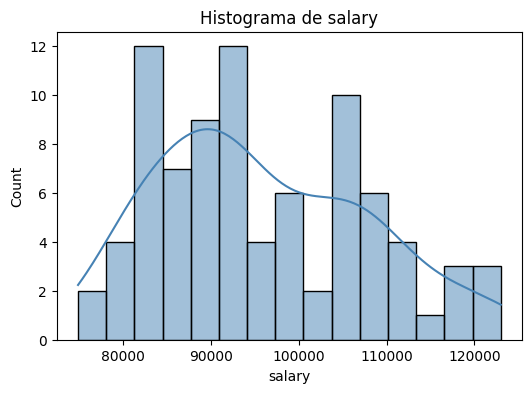

Asimetría de salary: 0.447


In [21]:
# Histograma de salary
plt.figure(figsize=(6, 4))
sns.histplot(df["salary"], bins=15, kde=True, color="steelblue")
plt.title("Histograma de salary")
plt.xlabel("salary")
plt.show()
print("Asimetría de salary:", round(df["salary"].skew(), 3))

**Respuesta (histograma):** El salario se concentra entre 80,000 y 110,000, con la mayor parte alrededor de 83,000-93,000, y una cola que se estira a la derecha hasta 123,000 (asimetría de 0.45, la media 95,899 está arriba de la mediana 93,200). No tiene una sola campana clara: se ven como dos o tres grupos (cerca de 83,000, de 92,000 y de 105,000), que podrían corresponder a distintos tipos de universidades o regiones.

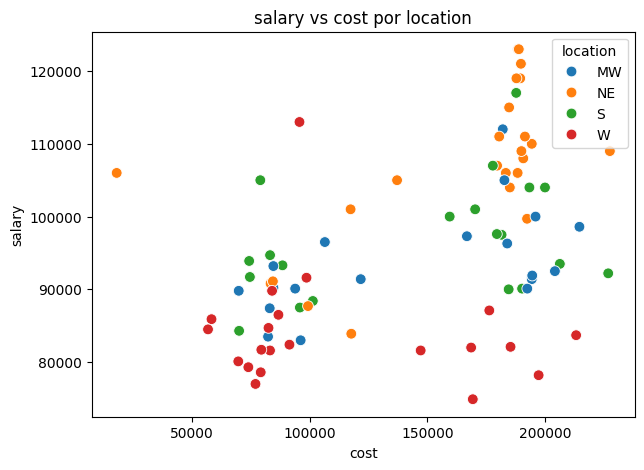

In [22]:
# Diagrama de dispersión salary vs cost, con color por location
plt.figure(figsize=(7, 5))
sns.scatterplot(x="cost", y="salary", hue="location", data=df, s=60)
plt.title("salary vs cost por location")
plt.show()

**Respuesta (dispersión):** Hay una tendencia positiva: a mayor costo, mayor salario. Los puntos forman dos grupos de costo: uno de universidades de menos de 120,000 (en su mayoría públicas) y otro de 160,000 a 230,000. Por región, NE (naranja) está arriba, con los salarios más altos, sobre todo los de costo alto (hasta 123,000). W (rojo) está abajo, casi todos por debajo de 90,000. MW y S quedan en medio y mezclados. Es decir, la región cambia el nivel del salario aparte del costo, lo que justifica meter `location` al modelo. Se ven algunos puntos raros, como una universidad del NE con costo de solo 18,260 y salario de 106,000, y una del W con salario de 113,000 y costo de 96,000.

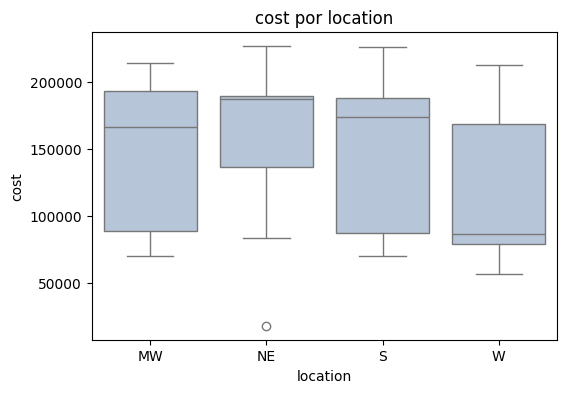

,cost
location,
MW,166700.0
NE,187700.0
S,173950.0
W,86820.0


In [23]:
# Boxplot de cost por location
plt.figure(figsize=(6, 4))
sns.boxplot(x="location", y="cost", data=df, color="lightsteelblue")
plt.title("cost por location")
plt.show()
df.groupby("location", observed=True)["cost"].median()

**Respuesta (boxplot):** Las medianas del costo son bastante distintas: W es la más baja (86,820) y las demás son altas (MW 166,700, S 173,950, NE 187,700). En W la caja es ancha y llega hasta 170,000, o sea que mezcla universidades baratas y caras. NE tiene la caja más angosta y arriba, y un valor atípico abajo (el de 18,260). Así que sí hay diferencias de costo según la ubicación, pero con mucha dispersión dentro de cada región y las cajas se traslapan, por lo que el costo solo no separa claramente las regiones.

# 3. Construcción del modelo de regresión

- Construye el modelo de regresión usando los datos de salario, costo y location. Recuerda que esta última debe ser en su versión codificada con one-hot encoding.
- Imprime los coeficientes e interpreta qué significan cuando se sustituyen valores en costo, y location (versión codificada). Si no recuerdas cómo se hace esta interpretación consulta los videos.


In [24]:
# Modelo de regresión: salary - cost + location (dummies)
X = pd.concat([df[["cost"]], location_dummies], axis=1)
y = df["salary"]

modelo = LinearRegression()
modelo.fit(X, y)

print("Intercepto:", round(modelo.intercept_, 2))
for variable, coef in zip(X.columns, modelo.coef_):
    print(f"Coeficiente de {variable}: {coef:.4f}")

Intercepto: 84988.72
Coeficiente de cost: 0.0605
Coeficiente de NE: 12032.8197
Coeficiente de S: 2800.3450
Coeficiente de W: -7721.4201


**Respuesta:** El modelo queda: salary = 84,989 + 0.0605·cost + 12,033·NE + 2,800·S − 7,721·W.
- **Intercepto (84,989):** salario esperado de una universidad de la región de referencia (MW) con costo 0.
- **cost (0.0605):** por cada dólar más de costo, el salario sube 0.06 (cada 10,000 más de costo, unos 605 más de salario), sin cambiar de región.
- **NE (12,033):** a mismo costo, una universidad del NE tiene en promedio 12,033 más de salario que una de MW.
- **S (2,800):** a mismo costo, una del S tiene 2,800 más que una de MW (diferencia chica, que más abajo no resulta significativa).
- **W (−7,721):** a mismo costo, una del W tiene 7,721 menos que una de MW.

Al sustituir, para MW las tres dummies valen 0 (queda 84,989 + 0.0605·cost). Para NE se suma 12,033 al intercepto, y lo mismo con S (2,800) y W (−7,721). Es decir, las cuatro regiones tienen la misma pendiente y solo cambia el punto de partida.

# 4. Análisis de Residuos

- Construyen una visualización de predicciones (salario estimado) vs valores reales (salario real).
- Crea una gráfica de los errores residuales. Discute lo que observas

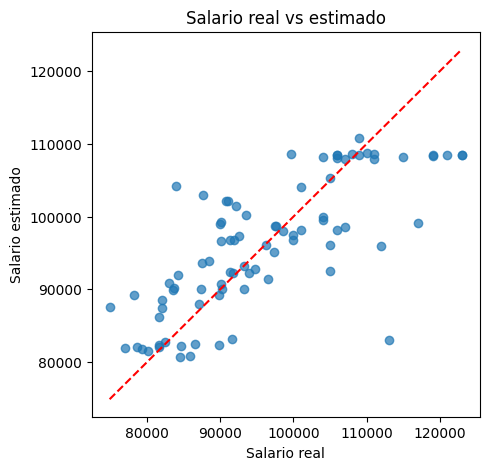

In [25]:
# Predicciones vs valores reales
y_pred = modelo.predict(X)
residuos = y - y_pred

plt.figure(figsize=(5, 5))
plt.scatter(y, y_pred, alpha=0.7)
plt.plot([y.min(), y.max()], [y.min(), y.max()], color="red", linestyle="--")
plt.xlabel("Salario real")
plt.ylabel("Salario estimado")
plt.title("Salario real vs estimado")
plt.show()

**Respuesta (reales vs estimados):** Los puntos siguen la tendencia de la diagonal pero con bastante dispersión: el modelo capta la relación general, y no es muy preciso. Subestima a las universidades de salario muy alto (los de 115,000-123,000 se estiman en unos 108,000) y sobreestima a unas pocas de salario bajo. Se ve el mismo R² moderado de la siguiente parte.

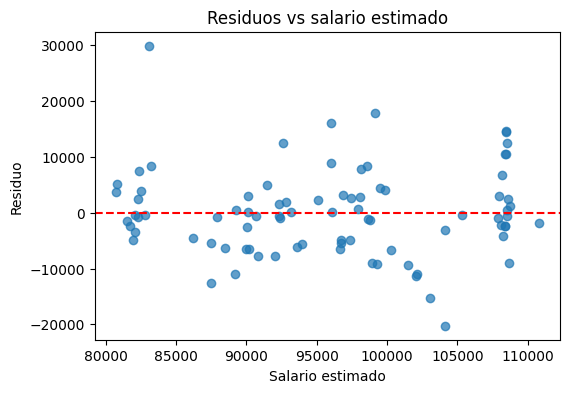

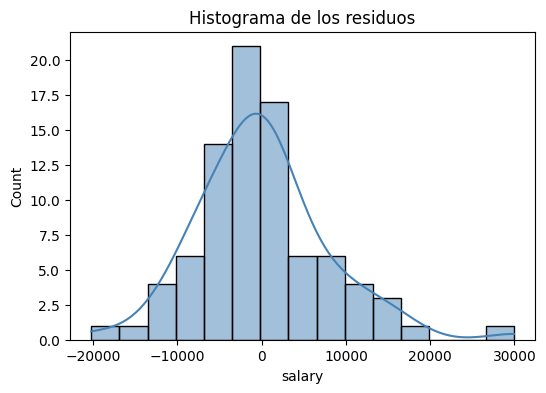

Residuo mínimo: -20244  Residuo máximo: 29939


In [26]:
# Errores residuales
plt.figure(figsize=(6, 4))
plt.scatter(y_pred, residuos, alpha=0.7)
plt.axhline(0, color="red", linestyle="--")
plt.xlabel("Salario estimado")
plt.ylabel("Residuo")
plt.title("Residuos vs salario estimado")
plt.show()

plt.figure(figsize=(6, 4))
sns.histplot(residuos, bins=15, kde=True, color="steelblue")
plt.title("Histograma de los residuos")
plt.show()
print("Residuo mínimo:", round(residuos.min()), " Residuo máximo:", round(residuos.max()))

**Respuesta (residuos):** Los residuos se reparten alrededor de cero sin un patrón fuerte ni abanico, así que el modelo lineal no es un mal punto de partida. Hay un grupo de residuos positivos grandes en estimados cercanos a 108,000 (universidades del NE con salarios de 115,000-123,000 que el modelo no alcanza a predecir) y un residuo muy grande de casi +30,000 (la universidad del W con salario de 113,000). El residuo más negativo es de −20,244. El histograma es aproximadamente simétrico con una cola a la derecha por esos casos. Los errores van de −20,244 a +29,939.

# 5. Evalúa el modelo

- Calcula el MSE del modelo construido. Recuerda que usas el propio conjunto de datos (No hablamos nada de entrenamiento y test).
- Calcula el R² Score

Discute estos resultados obtenidos.

In [27]:
# MSE y R² (con el mismo conjunto de datos, sin train/test)
mse = mean_squared_error(y, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y, y_pred)

print(f"MSE: {mse:,.0f}")
print(f"RMSE: {rmse:,.0f}")
print(f"R²: {r2:.4f}")

MSE: 60,480,269
RMSE: 7,777
R²: 0.5705


**Respuesta:** MSE = 60,480,269, que equivale a un RMSE de 7,777: en promedio las predicciones se equivocan por unos 7,800 de salario (el salario promedio es de 95,899, o sea cerca de un 8%). R² = 0.5705, es decir que el costo y la región explican cerca del 57% de la variación del salario. Es un ajuste moderado: sirve para ver la tendencia, pero casi la mitad de la variación queda sin explicar, así que hay otros factores (tipo de universidad, carrera, etc.) que no están en el modelo. Hay que recordar que el MSE y el R² se calcularon sobre los mismos datos con los que se ajustó el modelo, entonces el desempeño con datos nuevos probablemente sería algo peor.

# 6. Realiza un análisis de varianza con stastmodel

Consulta esto aquí https://www.statsmodels.org/dev/examples/notebooks/generated/variance_components.html

In [28]:
# Análisis de varianza (ANOVA) con statsmodels
modelo_ols = smf.ols("salary ~ cost + C(location)", data=df).fit()
print(modelo_ols.summary())

tabla_anova = sm.stats.anova_lm(modelo_ols, typ=2)
tabla_anova

                            OLS Regression Results                            
Dep. Variable:                 salary   R-squared:                       0.571
Model:                            OLS   Adj. R-squared:                  0.549
Method:                 Least Squares   F-statistic:                     26.57
Date:                Mon, 02 Nov 2026   Prob (F-statistic):           4.96e-14
Time:                        03:47:57   Log-Likelihood:                -882.12
No. Observations:                  85   AIC:                             1774.
Df Residuals:                      80   BIC:                             1786.
Df Model:                           4                                         
Covariance Type:            nonrobust                                         
                        coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------------
Intercept          8.499e+04   3092.65

,sum_sq,df,F,PR(>F)
C(location),4.071774e+09,3.0,21.121259,3.570975e-10
cost,7.878166e+08,1.0,12.259774,7.600629e-04
Residual,5.140823e+09,80.0,NaN,NaN


**Respuesta (ANOVA):** Con `anova_lm` (tipo II) se prueba cada variable después de considerar la otra. `location` tiene F = 21.12 y p = 3.6e-10, y `cost` tiene F = 12.26 y p = 0.00076. Los dos son menores a 0.05, así que ambos aportan al salario: hay diferencias significativas de salario entre regiones aun controlando el costo, y el costo también tiene efecto controlando la región. `location` tiene la mayor suma de cuadrados (4.07e9 contra 7.88e8 de `cost`), por lo que explica más variación del salario que el costo. En el resumen de OLS se ve que, por categoría, NE (p = 0.000) y W (p = 0.004) son distintas de MW, y S (p = 0.279) no lo es. La variación sin explicar (residual, 5.14e9) sigue siendo grande, de acuerdo con R² = 0.57.